# Segmentation des profils étudiants par K-Means

Ce travail cherche à identifier des profils d'étudiants à partir des caractéristiques retenues dans la première partie du projet. L'analyse repose sur K-Means implémenté avec NumPy, un choix de $K$ fondé sur plusieurs critères et une lecture descriptive des groupes. Les étiquettes académiques sont examinées seulement après la sélection du modèle, sur l'échantillon de test.

## 1. Données et préparation

Les partitions d'entraînement et de test ainsi que la sélection des variables sont conservées. Les transformations sont appliquées à l'aide des fonctions de prétraitement définies dans la première partie, où leur justification est présentée. Les paramètres sont ajustés exclusivement sur l'entraînement.

In [1]:
import json
import sys
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

SEED = 42
CLASSES = ["Dropout", "Enrolled", "Graduate"]
ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / "data_split" / "selected_features.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Répertoire du projet introuvable : data_split/ est requis.")

with (ROOT / "data_split" / "selected_features.json").open(encoding="utf-8") as file:
    selection = json.load(file)

features = selection["selected_features"]
NUMERIC = selection["numeriques"]
BINARY = selection["binaires"][0]
CATEGORICAL = selection["nominales"][0]
SPLIT = ROOT / "data_split"
X_train_raw = pd.read_csv(SPLIT / "X_train.csv").reset_index(drop=True)
X_test_raw = pd.read_csv(SPLIT / "X_test.csv").reset_index(drop=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from P1.preprocessing import fit_preprocessor, transform_preprocessor

preprocessor = fit_preprocessor(X_train_raw, features, min_count=20)
train_encoded = transform_preprocessor(X_train_raw, preprocessor)
test_encoded = transform_preprocessor(X_test_raw, preprocessor)
X_train = train_encoded.to_numpy(dtype=float)
X_test = test_encoded.to_numpy(dtype=float)

print(f"Entraînement : {X_train.shape[0]} étudiants, {X_train.shape[1]} variables encodées")
print(f"Test : {X_test.shape[0]} étudiants")
print("Variables sélectionnées :", ", ".join(features))

Entraînement : 3539 étudiants, 20 variables encodées
Test : 885 étudiants
Variables sélectionnées : Curricular units 2nd sem (approved), Tuition fees up to date, Course, Curricular units 1st sem (evaluations)


## 2. Fondements et implémentation de K-Means

Chaque étudiant est représenté par un vecteur $x_i\in\mathbb{R}^{p}$, avec $p=20$ après encodage. Pour un nombre de groupes $K$ fixé, K-Means recherche les affectations $z_i$ et les centroïdes $\mu_j$ qui minimisent l'**inertie intra-classe** :

$$
J=\sum_{i=1}^{n}\left\|x_i-\mu_{z_i}\right\|_2^2.
$$

### Algorithme de Lloyd

L'optimisation alterne deux opérations : affecter chaque étudiant au centroïde le plus proche, puis recalculer chaque centroïde comme moyenne des observations de son groupe.

$$
z_i\leftarrow\arg\min_{j\in\{0,\ldots,K-1\}}\|x_i-\mu_j\|_2^2,
\qquad
\mu_j\leftarrow\frac{1}{|C_j|}\sum_{i\in C_j}x_i.
$$

La moyenne minimise la somme des écarts quadratiques pour des affectations fixées, puisque $\nabla_{\mu}\sum_{i\in C}\|x_i-\mu\|^2=0$ conduit à $\mu=|C|^{-1}\sum_{i\in C}x_i$. Les étapes de Lloyd ne font donc pas augmenter l'inertie, mais le résultat dépend des centres de départ : il peut correspondre à un **minimum local**. L'arrêt intervient lorsque les affectations se stabilisent, que les centroïdes bougent de moins que `tol`, ou que `max_iter` est atteint. Les groupes vides sont traités par réaffectation d'une observation.

### Distances et initialisation

Le calcul des distances est vectorisé avec l'identité :

$$
\boxed{\|x-\mu\|_2^2=\|x\|_2^2+\|\mu\|_2^2-2x^{\top}\mu.}
$$

Elle permet de construire la matrice des distances entre les $n$ étudiants et les $K$ centroïdes, notamment grâce au produit matriciel `X @ centers.T`. La complexité d'une itération reste de l'ordre de $O(nKp)$, mais les opérations sont exécutées efficacement par NumPy.

L'initialisation **K-Means++** tire d'abord un centre au hasard, puis privilégie les observations éloignées des centres déjà retenus. Si $D(x_i)^2$ désigne la distance quadratique au centre choisi le plus proche :

$$
P(x_i)=\frac{D(x_i)^2}{\sum_{r=1}^{n}D(x_r)^2}.
$$

Les observations répétées restent présentes dans ce tirage. Pour limiter la sensibilité à l'initialisation, `n_init=10` exécutions indépendantes sont réalisées et seule la partition de **plus faible inertie** est conservée. Cette stratégie améliore la robustesse sans garantir l'optimum global.


In [2]:
def squared_distances(X, centers):
    return np.maximum(
        np.sum(X * X, axis=1)[:, None]
        + np.sum(centers * centers, axis=1)[None, :]
        - 2 * X @ centers.T,
        0.0,
    )


class KMeansFromScratch:
    def __init__(self, k, init="kmeans++", n_init=10, max_iter=120, tol=1e-6, seed=42):
        self.k = k
        self.init = init
        self.n_init = n_init
        self.max_iter = max_iter
        self.tol = tol
        self.seed = seed

    def _initial_centers(self, X, rng):
        n = len(X)
        if self.k > n:
            raise ValueError("K ne peut pas dépasser le nombre d'observations.")
        if self.init == "random":
            return X[rng.choice(n, size=self.k, replace=False)].copy()
        if self.init != "kmeans++":
            raise ValueError("Initialisation non reconnue.")

        chosen = [int(rng.integers(n))]
        nearest = squared_distances(X, X[chosen]).ravel()
        while len(chosen) < self.k:
            weights = nearest.copy()
            weights[chosen] = 0.0
            total = weights.sum()
            if total > 1e-12:
                index = int(rng.choice(n, p=weights / total))
            else:
                remaining = np.setdiff1d(np.arange(n), np.asarray(chosen), assume_unique=True)
                index = int(rng.choice(remaining))
            chosen.append(index)
            nearest = np.minimum(nearest, squared_distances(X, X[[index]]).ravel())
        return X[chosen].copy()

    def _run(self, X, rng):
        centers = self._initial_centers(X, rng)
        previous_labels = None
        for iteration in range(1, self.max_iter + 1):
            distances = squared_distances(X, centers)
            labels = distances.argmin(axis=1)
            counts = np.bincount(labels, minlength=self.k)
            for empty in np.flatnonzero(counts == 0):
                options = np.flatnonzero(counts[labels] > 1)
                selected = int(options[np.argmax(distances[options, labels[options]])])
                counts[labels[selected]] -= 1
                labels[selected] = empty
                counts[empty] += 1

            new_centers = np.vstack([X[labels == j].mean(axis=0) for j in range(self.k)])
            shift = np.linalg.norm(new_centers - centers)
            stable = previous_labels is not None and np.array_equal(labels, previous_labels)
            centers = new_centers
            if stable or shift <= self.tol:
                break
            previous_labels = labels.copy()

        final_distances = squared_distances(X, centers)
        final_labels = final_distances.argmin(axis=1)
        inertia = float(final_distances[np.arange(len(X)), final_labels].sum())
        return centers, final_labels, inertia, iteration

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.isfinite(X).all() or self.k < 2 or self.n_init < 1:
            raise ValueError("Données ou paramètres invalides.")
        generator = np.random.default_rng(self.seed)
        best = None
        for _ in range(self.n_init):
            rng = np.random.default_rng(int(generator.integers(0, 2**32)))
            result = self._run(X, rng)
            if best is None or result[2] < best[2]:
                best = result
        self.centers_, self.labels_, self.inertia_, self.n_iter_ = best
        return self

    def predict(self, X):
        return squared_distances(np.asarray(X, float), self.centers_).argmin(axis=1)

Les fonctions suivent directement ces étapes : `squared_distances` calcule les distances, `_initial_centers` prépare les centroïdes, `_run` effectue les itérations de Lloyd, `fit` retient le meilleur redémarrage et `predict` affecte de nouvelles observations sans réentraîner le modèle. Les valeurs numériques standardisées et les indicatrices de `Course` sont traitées dans le même espace euclidien ; l'effet de ce choix sur les profils sera discuté avec les résultats.

## 3. Sélection multicritère du nombre de groupes

L'inertie $J$ mesure la compacité, mais diminue généralement lorsque $K$ augmente : elle ne suffit donc pas à choisir le nombre de groupes.

### Silhouette : cohésion et séparation

Pour un étudiant $i$, $a(i)$ est sa distance moyenne aux autres membres de son cluster et $b(i)$ la plus petite distance moyenne vers un autre cluster :

$$
a(i)=\frac{1}{|C_{z_i}|-1}\sum_{r\in C_{z_i},\,r\ne i}d(x_i,x_r),
\qquad
b(i)=\min_{g\ne z_i}\frac{1}{|C_g|}\sum_{r\in C_g}d(x_i,x_r).
$$

$$
\boxed{s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}\in[-1,1].}
$$

Une silhouette proche de 1 traduit une bonne séparation ; proche de 0, un chevauchement ; négative, une affectation moins cohérente avec les distances. La moyenne est estimée sur plusieurs sous-échantillons, avec les **distances euclidiennes non élevées au carré**. Pour un groupe singleton, la silhouette vaut 0 par convention.

### ARI : stabilité des partitions

L'**Adjusted Rand Index (ARI)** compare deux partitions des mêmes étudiants indépendamment du numéro attribué aux clusters, en corrigeant l'accord attendu par hasard. Il utilise une table de contingence $n_{ij}$ entre les deux partitions. Avec $a_i=\sum_j n_{ij}$, $b_j=\sum_i n_{ij}$ et $B(v)=v(v-1)/2$ :

$$
\mathrm{ARI}=\frac{\sum_{ij}B(n_{ij})-E}{\tfrac12\left[\sum_i B(a_i)+\sum_j B(b_j)\right]-E},
\qquad
E=\frac{\left(\sum_i B(a_i)\right)\left(\sum_j B(b_j)\right)}{B(n)}.
$$

Un ARI proche de 1 indique des partitions très similaires ; une valeur proche de 0 correspond à un accord comparable au hasard. Il mesure la **reproductibilité**, non la qualité académique des groupes.

### Règle de décision

Nous explorons $K=2$ à $30$. Une valeur est admissible si l'**ARI moyen est au moins 0,90** et si **chaque cluster contient au moins 1 % de Train**. Parmi ces valeurs, nous retenons celle de meilleure silhouette moyenne. L'inertie et la répartition des effectifs complètent la discussion. Ces seuils sont des choix méthodologiques, non des propriétés universelles ; aucune étiquette `Target` du test n'intervient dans la sélection.


In [3]:
def silhouette_from_distances(distances, labels):
    _, group = np.unique(np.asarray(labels), return_inverse=True)
    k = group.max() + 1
    n = len(group)
    if k < 2 or k >= n:
        return np.nan
    membership = (group[:, None] == np.arange(k)).astype(float)
    sizes = membership.sum(axis=0)
    sums = distances @ membership
    rows = np.arange(n)
    a = sums[rows, group] / np.maximum(sizes[group] - 1, 1)
    means = sums / sizes
    means[rows, group] = np.inf
    b = means.min(axis=1)
    denominator = np.maximum(a, b)
    scores = np.divide(b - a, denominator, out=np.zeros(n), where=denominator > 0)
    scores[sizes[group] == 1] = 0
    return float(scores.mean())


def adjusted_rand_from_scratch(first, second):
    _, a = np.unique(first, return_inverse=True)
    _, b = np.unique(second, return_inverse=True)
    if len(a) != len(b):
        raise ValueError("Les partitions doivent porter sur les mêmes observations.")
    table = np.zeros((a.max() + 1, b.max() + 1), dtype=np.int64)
    np.add.at(table, (a, b), 1)

    def pairs(counts):
        return np.sum(counts * (counts - 1) // 2)

    agreement = pairs(table)
    row_pairs = pairs(table.sum(axis=1))
    col_pairs = pairs(table.sum(axis=0))
    total_pairs = len(a) * (len(a) - 1) / 2
    if total_pairs == 0:
        return 1.0
    expected = row_pairs * col_pairs / total_pairs
    maximum = (row_pairs + col_pairs) / 2
    return float((agreement - expected) / (maximum - expected)) if maximum != expected else 1.0


SAMPLE_SIZE = min(650, len(X_train))
SAMPLE_SEEDS = [103, 104, 105]
SAMPLE_INDICES = [np.random.default_rng(seed).choice(len(X_train), SAMPLE_SIZE, replace=False)
                  for seed in SAMPLE_SEEDS]
SAMPLE_DISTANCES = [np.sqrt(squared_distances(X_train[idx], X_train[idx]))
                    for idx in SAMPLE_INDICES]
for distance_matrix in SAMPLE_DISTANCES:
    np.fill_diagonal(distance_matrix, 0.0)


def sampled_silhouette(model):
    return [silhouette_from_distances(d, model.predict(X_train[idx]))
            for d, idx in zip(SAMPLE_DISTANCES, SAMPLE_INDICES)]

### Protocole de recherche

Pour chaque $K$, quatre graines indépendantes sont utilisées, avec dix initialisations par entraînement. L'ARI moyen résume les six comparaisons entre partitions sur **tout Train**. La silhouette est calculée sur **trois échantillons fixes de 650 étudiants**, identiques d'un modèle à l'autre, afin de limiter le coût quadratique des distances entre observations. L'écart-type observé renseigne sur la sensibilité à l'échantillonnage.


K retenu : 3 | meilleur K selon silhouette seule : 30
Seuil de taille : 36 étudiants sur 3539


,K,Silhouette,Écart-type silhouette,ARI,Inertie,Plus petit groupe,Plus grand groupe (%),Admissible
0,2,0.2853,0.0118,1.0000,7950.5572,972,72.5346,True
1,3,0.3082,0.0101,0.9886,6566.4915,214,69.2286,True
2,4,0.2807,0.0076,0.9930,5373.2660,192,55.1851,True
3,5,0.2424,0.0111,0.9953,4807.3550,188,41.6784,True
4,6,0.2489,0.0112,0.9998,4382.2690,168,39.6440,True
5,7,0.2481,0.0127,0.9813,4166.8931,75,40.6329,True
6,8,0.2489,0.0146,0.7525,3979.5763,60,34.8686,False
7,9,0.2580,0.0141,0.7493,3810.9052,60,30.4606,False
8,10,0.2832,0.0267,0.6380,3667.8381,62,25.9960,False
9,11,0.2969,0.0254,0.6492,3512.0577,61,24.6115,False


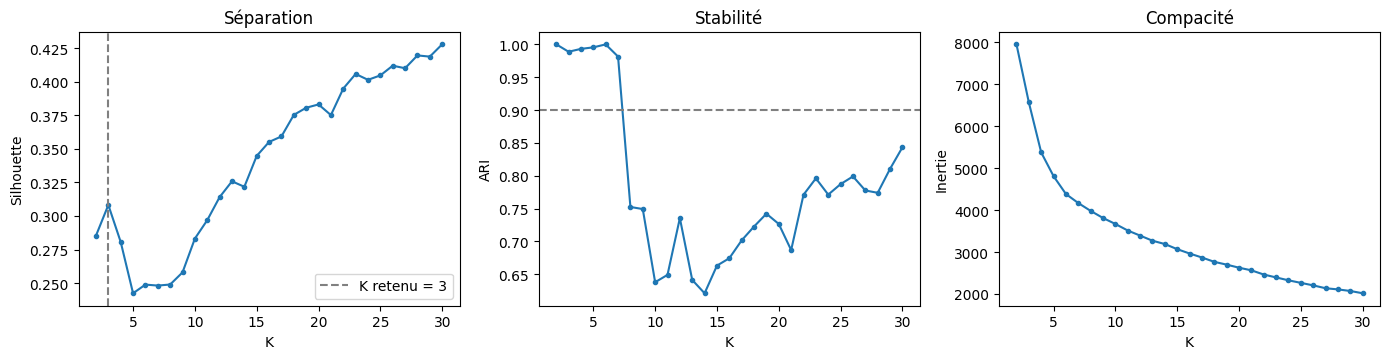

In [4]:
K_VALUES = range(2, 31)
SEEDS = [21, 42, 63, 84]
N_INIT = 10
MIN_SIZE = int(np.ceil(0.01 * len(X_train)))
models_by_k = {}
selection_rows = []

for k in K_VALUES:
    models = [KMeansFromScratch(k, n_init=N_INIT, seed=seed).fit(X_train)
              for seed in SEEDS]
    models_by_k[k] = models
    all_silhouettes = [value for model in models for value in sampled_silhouette(model)]
    all_ari = [adjusted_rand_from_scratch(a.labels_, b.labels_)
               for a, b in combinations(models, 2)]
    minimum_sizes = [np.bincount(model.labels_, minlength=k).min() for model in models]
    selection_rows.append({
        "K": k,
        "Silhouette": np.mean(all_silhouettes),
        "Écart-type silhouette": np.std(all_silhouettes),
        "ARI": np.mean(all_ari),
        "Inertie": np.mean([model.inertia_ for model in models]),
        "Plus petit groupe": min(minimum_sizes),
        "Plus grand groupe (%)": max(np.bincount(model.labels_, minlength=k).max()
                                    for model in models) / len(X_train) * 100,
    })

selection = pd.DataFrame(selection_rows)
selection["Admissible"] = ((selection["ARI"] >= 0.90)
                           & (selection["Plus petit groupe"] >= MIN_SIZE))
eligible = selection[selection["Admissible"]]
if eligible.empty:
    raise ValueError("Aucune valeur de K ne satisfait les critères définis ; réexaminer les seuils.")
final_k = int(eligible.sort_values(["Silhouette", "K"], ascending=[False, True]).iloc[0]["K"])
k_best_silhouette = int(selection.loc[selection["Silhouette"].idxmax(), "K"])

print(f"K retenu : {final_k} | meilleur K selon silhouette seule : {k_best_silhouette}")
print(f"Seuil de taille : {MIN_SIZE} étudiants sur {len(X_train)}")
display(selection.round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
axes[0].plot(selection["K"], selection["Silhouette"], marker=".")
axes[0].axvline(final_k, linestyle="--", color="gray", label=f"K retenu = {final_k}")
axes[0].set(xlabel="K", ylabel="Silhouette", title="Séparation")
axes[0].legend()
axes[1].plot(selection["K"], selection["ARI"], marker=".")
axes[1].axhline(0.90, linestyle="--", color="gray")
axes[1].set(xlabel="K", ylabel="ARI", title="Stabilité")
axes[2].plot(selection["K"], selection["Inertie"], marker=".")
axes[2].set(xlabel="K", ylabel="Inertie", title="Compacité")
plt.tight_layout()
plt.show()

### Résultat de la sélection

La décision confronte séparation géométrique, stabilité et taille minimale des groupes. La meilleure silhouette de l'ensemble exploré reste indiquée, même si le modèle correspondant ne satisfait pas les critères d'admissibilité. Le $K$ retenu est celui défini par la règle précédente, **avant toute analyse des étiquettes réelles**.


In [5]:
decision = selection.loc[selection["K"].isin(sorted(set([final_k, k_best_silhouette, 3, 5, 8, 20])))].copy()
display(decision[["K", "Silhouette", "ARI", "Inertie", "Plus petit groupe", "Admissible"]].round(4))

retained_row = selection.set_index("K").loc[final_k]
leading_row = selection.set_index("K").loc[k_best_silhouette]
print(f"Décision : K={final_k} (silhouette {retained_row['Silhouette']:.3f}, "
      f"ARI {retained_row['ARI']:.3f}, plus petit groupe {int(retained_row['Plus petit groupe'])}).")
print(f"Le maximum de silhouette est atteint à K={k_best_silhouette} "
      f"({leading_row['Silhouette']:.3f}), avec ARI {leading_row['ARI']:.3f} "
      f"et plus petit groupe {int(leading_row['Plus petit groupe'])}.")
if k_best_silhouette == max(K_VALUES):
    print("Ce maximum se trouve au bord de la grille et ne constitue pas un optimum global démontré.")

,K,Silhouette,ARI,Inertie,Plus petit groupe,Admissible
1,3,0.3082,0.9886,6566.4915,214,True
3,5,0.2424,0.9953,4807.3550,188,True
6,8,0.2489,0.7525,3979.5763,60,False
18,20,0.3831,0.7266,2625.7787,7,False
28,30,0.4279,0.8433,2016.5029,14,False


Décision : K=3 (silhouette 0.308, ARI 0.989, plus petit groupe 214).
Le maximum de silhouette est atteint à K=30 (0.428), avec ARI 0.843 et plus petit groupe 14.
Ce maximum se trouve au bord de la grille et ne constitue pas un optimum global démontré.


## 4. Modèle final et initialisation

Après la sélection de $K$, le modèle final est entraîné avec **K-Means++ et dix redémarrages**. L'effet de l'initialisation est ensuite étudié au même $K$ en comparant les variantes *Random* et *K-Means++*, avec un ou dix redémarrages. Nous observons l'inertie, la silhouette, leur variabilité entre graines et le temps d'exécution. Une faible inertie indique une meilleure optimisation de l'objectif de K-Means ; elle ne garantit pas une meilleure silhouette. K-Means++ est une stratégie de départ, **pas une garantie de supériorité** à chaque expérience.


In [6]:
start = time.perf_counter()
final_model = KMeansFromScratch(final_k, init="kmeans++", n_init=N_INIT, seed=SEED).fit(X_train)
final_elapsed = time.perf_counter() - start
final_silhouette = float(np.mean(sampled_silhouette(final_model)))
final_counts = np.bincount(final_model.labels_, minlength=final_k)
print(f"K = {final_k} | inertie = {final_model.inertia_:.2f} | silhouette = {final_silhouette:.4f}")
print(f"Itérations = {final_model.n_iter_} | plus petit groupe = {final_counts.min()}")

variants = [("Random × 1", "random", 1), ("K-Means++ × 1", "kmeans++", 1),
            ("Random × 10", "random", 10), ("K-Means++ × 10", "kmeans++", 10)]
benchmark_rows = []
for label, method, n_start in variants:
    for seed in SEEDS:
        t0 = time.perf_counter()
        model = KMeansFromScratch(final_k, init=method, n_init=n_start, seed=seed).fit(X_train)
        duration = time.perf_counter() - t0
        benchmark_rows.append({"Initialisation": label, "Inertie": model.inertia_,
                               "Silhouette": np.mean(sampled_silhouette(model)),
                               "Temps (s)": duration})

benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.groupby("Initialisation", sort=False)[["Inertie", "Silhouette", "Temps (s)"]]
        .agg(["mean", "std"]).round(4))

K = 3 | inertie = 6566.38 | silhouette = 0.3080
Itérations = 5 | plus petit groupe = 214


Inertie          Silhouette         Temps (s)        
                     mean      std       mean     std      mean     std
Initialisation                                                         
Random × 1      6690.0881  56.2320     0.2790  0.0082    0.0097  0.0048
K-Means++ × 1   6585.3025  37.3950     0.3029  0.0110    0.0088  0.0033
Random × 10     6585.9658  36.9766     0.3037  0.0122    0.1064  0.0061
K-Means++ × 10  6566.4915   0.1561     0.3082  0.0003    0.1035  0.0154

## 5. Comparaison finale avec Scikit-learn

La comparaison de référence est effectuée **une seule fois**, après fixation de $K$, avec les mêmes données et dix initialisations. L'inertie vérifie la qualité de la solution obtenue, tandis que l'ARI entre les deux partitions mesure l'accord des regroupements, indépendamment de leurs numéros. Les temps d'exécution sont présentés à titre indicatif. Des écarts restent possibles en raison des variantes d'initialisation et des critères d'arrêt ; une concordance sur ce jeu de données ne constitue pas une preuve générale de correction.


In [7]:
from sklearn.cluster import KMeans

t0 = time.perf_counter()
reference = KMeans(n_clusters=final_k, init="k-means++", n_init=N_INIT,
                   max_iter=120, tol=1e-6, random_state=SEED, algorithm="lloyd").fit(X_train)
reference_elapsed = time.perf_counter() - t0
agreement = adjusted_rand_from_scratch(final_model.labels_, reference.labels_)
reference_silhouette = float(np.mean([
    silhouette_from_distances(d, reference.predict(X_train[idx]))
    for d, idx in zip(SAMPLE_DISTANCES, SAMPLE_INDICES)
]))
benchmark_final = pd.DataFrame({
    "Implémentation": ["NumPy", "Scikit-learn"],
    "Inertie": [final_model.inertia_, reference.inertia_],
    "Silhouette": [final_silhouette, reference_silhouette],
    "Temps (s)": [final_elapsed, reference_elapsed],
})
display(benchmark_final.round(4))
print(f"ARI entre les deux partitions : {agreement:.4f}")

,Implémentation,Inertie,Silhouette,Temps (s)
0,NumPy,6566.3846,0.308,0.0918
1,Scikit-learn,6566.3846,0.308,0.0272


ARI entre les deux partitions : 1.0000


## 6. Centroïdes et profils des groupes

Après avoir fixé $K$, nous examinons ce que caractérise chaque groupe. Les centroïdes représentent les moyennes dans l'espace utilisé par K-Means. Pour les interpréter, nous revenons aux unités d'origine : $x = \mu_{\mathrm{train}} + z\,\sigma_{\mathrm{train}}$ pour les variables standardisées ; la moyenne de la variable binaire correspond à la proportion de frais à jour. Les coordonnées du bloc `Course` représentent les proportions des catégories *encodées*.

Nous confrontons ensuite ces centres aux statistiques calculées directement sur les observations brutes de **Train**. Les moyennes numériques et les proportions de frais doivent coïncider. Pour `Course`, un regroupement des catégories rares pendant l'encodage peut expliquer une différence avec la catégorie dominante des données brutes. Les noms des profils reposent uniquement sur ces caractéristiques, sans utiliser `Target`.

In [8]:
def centroid_table(model, params, columns):
    encoded = pd.DataFrame(model.centers_, columns=columns)
    result = pd.DataFrame(index=pd.Index(range(model.k), name="Cluster"))
    result["Effectif train"] = np.bincount(model.labels_, minlength=model.k)
    for variable in params["num"]:
        result[variable] = encoded[variable] * params["std"][variable] + params["mean"][variable]
    for variable in params["bin"]:
        result[variable + " (%)"] = encoded[variable] * 100
    for variable in params["nom"]:
        cols = [col for col in columns if col.startswith(variable + "=")]
        result["Course dominant"] = encoded[cols].idxmax(axis=1).str.split("=", n=1).str[-1].to_numpy()
        result["Part dominante (%)"] = encoded[cols].max(axis=1).to_numpy() * 100
    return result


def describe_profiles(raw, assignments):
    frame = raw[[*NUMERIC, BINARY, CATEGORICAL]].copy()
    frame["Cluster"] = assignments
    grouped = frame.groupby("Cluster")
    table = grouped[NUMERIC].mean()
    table.insert(0, "Effectif train", grouped.size())
    table["Frais à jour (%)"] = grouped[BINARY].mean() * 100
    table["Course dominant"] = grouped[CATEGORICAL].agg(lambda s: s.value_counts().index[0])
    table["Part dominante (%)"] = grouped[CATEGORICAL].agg(
        lambda s: s.value_counts(normalize=True).iloc[0] * 100)
    return table

centroids = centroid_table(final_model, preprocessor, train_encoded.columns)
profiles = describe_profiles(X_train_raw, final_model.labels_)
print("Centroïdes, dans les unités d'origine :")
display(centroids.round(2))
print("Description des étudiants de chaque groupe :")
display(profiles.round(2))

Centroïdes, dans les unités d'origine :


,Effectif train,Curricular units 2nd sem (approved),Curricular units 1st sem (evaluations),Tuition fees up to date (%),Course dominant,Part dominante (%)
Cluster,,,,,,
0,875,0.37,5.33,71.09,171,17.03
1,2450,5.40,8.53,94.04,9500,22.37
2,214,9.94,17.65,90.65,9003,19.16


Description des étudiants de chaque groupe :


,Effectif train,Curricular units 2nd sem (approved),Curricular units 1st sem (evaluations),Frais à jour (%),Course dominant,Part dominante (%)
Cluster,,,,,,
0,875,0.37,5.33,71.09,171,17.03
1,2450,5.40,8.53,94.04,9500,22.37
2,214,9.94,17.65,90.65,9003,19.16


In [9]:
ordered = profiles.sort_values(NUMERIC[0]).index.tolist()
if len(ordered) == 3:
    names = ["Validation académique faible", "Validation académique intermédiaire",
             "Validation académique élevée"]
else:
    names = [f"Profil académique {i+1}" for i in range(len(ordered))]
profile_names = {cluster: label for cluster, label in zip(ordered, names)}
for cluster in sorted(profile_names):
    item = profiles.loc[cluster]
    print(f"Cluster {cluster} — {profile_names[cluster]} : "
          f"{int(item['Effectif train'])} étudiants, "
          f"{item[NUMERIC[0]]:.2f} unités validées au semestre 2, "
          f"{item[NUMERIC[1]]:.2f} évaluations au semestre 1, "
          f"{item['Frais à jour (%)']:.1f} % de frais à jour.")

Cluster 0 — Validation académique faible : 875 étudiants, 0.37 unités validées au semestre 2, 5.33 évaluations au semestre 1, 71.1 % de frais à jour.
Cluster 1 — Validation académique intermédiaire : 2450 étudiants, 5.40 unités validées au semestre 2, 8.53 évaluations au semestre 1, 94.0 % de frais à jour.
Cluster 2 — Validation académique élevée : 214 étudiants, 9.94 unités validées au semestre 2, 17.65 évaluations au semestre 1, 90.7 % de frais à jour.


### Interprétation des profils

Le modèle retenu ($K=3$) distingue principalement trois niveaux de validation au second semestre, associés à des niveaux différents d'évaluations au premier semestre et de régularité des frais. Les deux indicateurs académiques concernent **des semestres différents** : leur rapport ne constitue donc pas un taux de réussite.

**Cluster 0 — validation très faible.** Ce groupe compte **875 étudiants (24,7 % du Train)**. Il présente en moyenne **0,37 unité validée au semestre 2** et **5,33 évaluations au semestre 1**. Les frais sont à jour pour **71,1 %** des étudiants, soit moins que dans les deux autres groupes. Ce profil combine une validation très limitée au second semestre et une moindre régularité administrative, sans permettre d'en déduire la cause.

**Cluster 1 — validation intermédiaire.** Avec **2 450 étudiants (69,2 %)**, c'est le groupe majoritaire. Les moyennes atteignent **5,40 unités validées** au second semestre et **8,53 évaluations** au premier ; **94,0 %** des étudiants ont leurs frais à jour. Son effectif important invite à rester prudent : ces moyennes peuvent masquer des situations individuelles variées.

**Cluster 2 — validation élevée.** Ce groupe réunit **214 étudiants (6,0 %)**. Il possède les valeurs moyennes les plus élevées des deux indicateurs académiques : **9,94 unités validées** au second semestre et **17,65 évaluations** au premier. La proportion de frais à jour est de **90,7 %**. Ces chiffres décrivent un volume de validation et d'évaluations plus important, sans démontrer un engagement supérieur ni une meilleure efficacité individuelle.

Le cursus le plus représenté ne dépasse pas **22,4 %** dans aucun des trois groupes. Aucun profil n'est donc associé à un seul `Course`, mais cette observation ne suffit pas à exclure l'influence de cette variable sur les distances et la segmentation. Les profils restent des descriptions de groupes, et non des catégories individuelles homogènes.

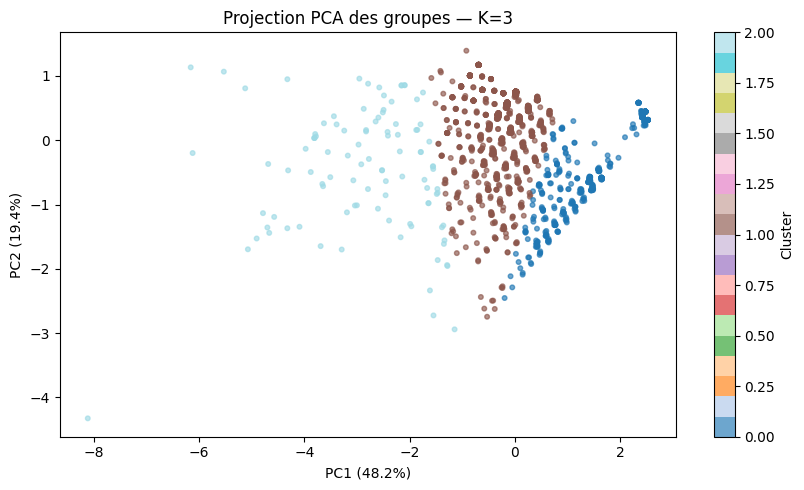

In [10]:
# Projection PCA calculée à partir de la matrice d'entraînement uniquement.
centered = X_train - X_train.mean(axis=0)
_, singular, vectors = np.linalg.svd(centered, full_matrices=False)
coordinates = centered @ vectors[:2].T
variance_explained = singular[:2]**2 / np.sum(singular**2)
subset = np.random.default_rng(SEED).choice(len(X_train),
                                               min(1800, len(X_train)), replace=False)
fig, ax = plt.subplots(figsize=(8.5, 5))
points = ax.scatter(coordinates[subset, 0], coordinates[subset, 1],
                    c=final_model.labels_[subset], cmap="tab20", s=11, alpha=0.65)
ax.set(xlabel=f"PC1 ({variance_explained[0]:.1%})", ylabel=f"PC2 ({variance_explained[1]:.1%})",
       title=f"Projection PCA des groupes — K={final_k}")
fig.colorbar(points, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

### Lecture de la projection PCA

La figure projette les **20 variables encodées** sur les deux directions qui expliquent le plus de variance dans **Train**. Les pourcentages des axes indiquent la variance représentée ; le reste de l'information est perdu dans cette projection. Un chevauchement visuel ne contredit donc pas nécessairement la partition calculée dans l'espace complet.

La silhouette moyenne d'environ **0,31** signale une **séparation modérée**, sans prouver l'existence de trois catégories naturellement distinctes. La PCA illustre la structure obtenue ; elle ne remplace pas les critères de sélection de $K$.

## 7. Analyse externe sur Test

Les étiquettes `Target` n'ont servi ni à entraîner K-Means ni à sélectionner $K$. Elles sont examinées ici **après fixation du modèle**, même si les quatre caractéristiques utilisées avaient été retenues auparavant par une sélection supervisée dans la première partie.

Chaque étudiant du jeu de test est affecté au centroïde appris sur **Train** le plus proche, sans réentraînement. Nous calculons ensuite les parts de `Dropout`, `Enrolled` et `Graduate`, ainsi que le lift de décrochage :

$$
\operatorname{Lift}(C_j)=\frac{P(\mathrm{Dropout}\mid C_j)}{P(\mathrm{Dropout})}.
$$

Un lift supérieur à 1 indique une proportion de décrochage plus élevée que dans l'ensemble de **Test**. Pour accompagner les pourcentages, nous présentons les effectifs et des intervalles de Wilson à 95 %, indicatifs de leur précision d'échantillonnage. Ces mesures décrivent des associations : elles ne constituent ni des prédictions individuelles ni des preuves de causalité.

Taux global de Dropout sur Test : 32.09%


Target,Effectif test,Profil,Dropout,Enrolled,Graduate,Lift Dropout,IC 95 % bas,IC 95 % haut
Cluster,,,,,,,,
0,207,Validation académique faible,78.74,14.98,6.28,2.45,72.67,83.77
1,621,Validation académique intermédiaire,18.36,19.48,62.16,0.57,15.51,21.59
2,57,Validation académique élevée,12.28,12.28,75.44,0.38,6.08,23.25


Cluster 0 (Validation académique faible) : 207 étudiants, Dropout 78.7 %, Enrolled 15.0 %, Graduate 6.3 % (lift 2.45).
Cluster 1 (Validation académique intermédiaire) : 621 étudiants, Dropout 18.4 %, Enrolled 19.5 %, Graduate 62.2 % (lift 0.57).
Cluster 2 (Validation académique élevée) : 57 étudiants, Dropout 12.3 %, Enrolled 12.3 %, Graduate 75.4 % (lift 0.38).


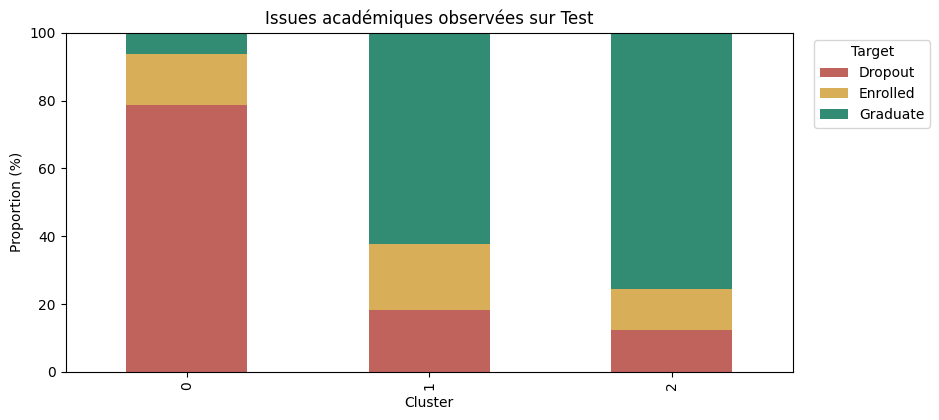

In [11]:
y_test = pd.read_csv(SPLIT / "y_test.csv").iloc[:, 0].reset_index(drop=True)
test_clusters = final_model.predict(X_test)
counts = pd.crosstab(pd.Series(test_clusters, name="Cluster"),
                     pd.Series(y_test.to_numpy(), name="Target"))
counts = counts.reindex(index=range(final_k), columns=CLASSES, fill_value=0)
percentages = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
outcomes = percentages.copy()
outcomes.insert(0, "Effectif test", counts.sum(axis=1))
base_dropout = float(np.mean(y_test.to_numpy() == "Dropout"))
outcomes["Lift Dropout"] = outcomes["Dropout"] / (100 * base_dropout)
outcomes.insert(1, "Profil", [profile_names[k] for k in outcomes.index])
# Intervalle de Wilson (95 %) pour la part de Dropout de chaque groupe.
n_test = counts.sum(axis=1).to_numpy(dtype=float)
n_dropout = counts["Dropout"].to_numpy(dtype=float)
z = 1.96
p_dropout = np.divide(n_dropout, n_test, out=np.zeros_like(n_dropout), where=n_test > 0)
n_safe = np.maximum(n_test, 1)
denominator = 1 + z**2 / n_safe
center = (p_dropout + z**2 / (2 * n_safe)) / denominator
margin = z * np.sqrt(p_dropout * (1 - p_dropout) / n_safe
                     + z**2 / (4 * n_safe**2)) / denominator
ci_low = np.where(n_test > 0, (center - margin) * 100, np.nan)
ci_high = np.where(n_test > 0, (center + margin) * 100, np.nan)
outcomes["IC 95 % bas"] = ci_low
outcomes["IC 95 % haut"] = ci_high

print(f"Taux global de Dropout sur Test : {base_dropout:.2%}")
display(outcomes.round(2))

for cluster, row in outcomes.iterrows():
    print(f"Cluster {cluster} ({profile_names[cluster]}) : "
          f"{int(row['Effectif test'])} étudiants, "
          f"Dropout {row['Dropout']:.1f} %, "
          f"Enrolled {row['Enrolled']:.1f} %, "
          f"Graduate {row['Graduate']:.1f} % "
          f"(lift {row['Lift Dropout']:.2f}).")

fig, ax = plt.subplots(figsize=(9.5, 4.3))
percentages[CLASSES].plot(kind="bar", stacked=True, ax=ax, color=["#bf635c", "#d8ae58", "#328c74"])
ax.set(xlabel="Cluster", ylabel="Proportion (%)", ylim=(0, 100),
       title="Issues académiques observées sur Test")
ax.legend(title="Target", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Interprétation des résultats sur Test

Sur les **885 étudiants** du jeu de test, le taux global observé de `Dropout` est de **32,09 %**.

**Le contraste majeur concerne le cluster 0.** Parmi ses **207 étudiants**, **78,7 %** sont en situation de décrochage, contre **18,4 %** dans le cluster 1 (**621 étudiants**) et **12,3 %** dans le cluster 2 (**57 étudiants**). Son lift atteint **2,45** : le décrochage y est donc environ deux fois et demie plus fréquent que dans l'ensemble de Test. Cette concentration est cohérente avec la très faible validation académique qui caractérise ce profil, sans établir de relation causale.

**La différence entre les clusters 1 et 2 est moins nette.** Leurs parts de diplômés sont respectivement de **62,2 %** et **75,4 %**, et leurs taux de décrochage de **18,4 %** et **12,3 %**. Toutefois, l'intervalle de Wilson du taux de décrochage du cluster 2 est large (environ **6,1 % à 23,2 %**) en raison de son faible effectif. Les intervalles des deux groupes se chevauchent : ces données ne suffisent pas, à elles seules, à établir une différence statistiquement nette de décrochage.

Le **cluster 1** rassemble près de **70 %** des étudiants de Test et présente des issues diverses : **18,4 % Dropout**, **19,5 % Enrolled** et **62,2 % Graduate**. Cette diversité souligne le caractère relativement grossier de la partition en trois groupes. Enfin, les proportions d'étudiants affectés à chaque groupe sont proches entre Train et Test ; cela indique une répartition similaire des effectifs, **sans suffire à démontrer à elle seule la généralisation** des profils.

## 8. Discussion et conclusion

La segmentation retenue est **$K=3$**, selon la règle annoncée avant l'analyse des étiquettes : **ARI moyen $\geq 0{,}90$**, effectif minimal d'au moins **1 %** du Train, puis meilleure silhouette parmi les valeurs admissibles. Sa silhouette d'environ **0,31** traduit une séparation modérée. L'implémentation NumPy et la référence Scikit-learn ont produit, dans cette exécution, la même partition (**ARI = 1**) et la même inertie.

L'analyse met surtout en évidence un profil à **très faible validation au second semestre**, associé sur Test à **78,7 % de décrochage**, contre **18,4 %** et **12,3 %** dans les deux autres groupes. La majorité des étudiants appartient toutefois au profil intermédiaire, qui demeure hétérogène. Le petit effectif du troisième groupe appelle aussi à la prudence dans l'interprétation des écarts.

Ces résultats dépendent du choix des variables et de leur encodage. Les caractéristiques ont été sélectionnées de manière supervisée en amont ; de plus, les unités validées au second semestre rendent l'analyse **rétrospective**, non utilisable telle quelle pour un repérage dès l'inscription. Ni les associations observées ni le lift ne démontrent une causalité ou une probabilité individuelle de décrochage. Une étude de sensibilité à `Course` et à d'autres valeurs de $K$ pourra compléter cette segmentation.